# 03 · DCGAN and conditional GAN
### The Class 4 notebook (GAN-Class-4-DCGAN-cGAN.ipynb), rebuilt and run

**Covers (GAN Class 4 slides):** revision of Classes 2 & 3 · the three diagnostic tools · why convolutions · Conv2d / ConvTranspose2d size formulas · the DCGAN recipe · conditional GAN (cGAN): give the label to **both** players · conditional accuracy · content vs style · the assignment.

**Where the code comes from.** The course guide *"GAN Class 4 Notebook Explained"* describes this notebook part by part, with its function names (`classify`, `train_gan`, `show_grid`, `digit_histogram`, `show_diagnostics`, `conv_out`, `convT_out`, `init_weights`, `CondDCGenerator`, `CondDCDiscriminator`, `conditional_accuracy`, `style_vs_content`, `interpolate`), architectures and defaults. This notebook follows it exactly. It also finishes the two "later" items from the Class 1 notebook: the **DCGAN generator skeleton** (cells 6–7, the CelebA mini-project) and the **conditional-GAN assignment** (cell 8).

The guide quotes numbers from the course's own test run (seed 0, a 2-core CPU). **The numbers in this notebook come from this run**; where they differ from the guide's, both are shown. Differences are expected: random seeds, library versions and hardware all change GAN results. Compare patterns, not exact numbers.

> **The training game does not change today.** Same losses, same alternating D step and G step, same Adam settings (lr 0.0002, β1 = 0.5) that Classes 2 & 3 showed to be more stable. We change **how G and D see images** (convolutions) and **what G is told** (the label).

| Part | What you do | Course CPU time (guide) |
|---|---|---|
| 0 | imports, device, load MNIST (batch 128) | seconds |
| 1 | revision quiz; CNN digit counter; `train_gan()`; Class 1 baseline | 29 s + 18 s |
| 2 | size formulas; the 2×2 → 4×4 stamp demo; Exercise 2 | instant |
| 3 | build, initialise and train the DCGAN; compare with the baseline; Exercise 3 | 153 s |
| 4 | conditional DCGAN; conditional accuracy; style vs content; interpolation; Exercise 4 | 199 s |
| 5 | wrap-up, reflection questions, assignment (option C done for real) | — |

Cells marked **✏️ Predict** ask for a guess before the next cell runs.

### Words you need

| Term | Plain meaning |
|---|---|
| **DCGAN** | Deep Convolutional GAN: G and D made of convolutions (Radford, Metz and Chintala 2015) |
| **Convolution (Conv2d)** | slides one small filter over the image; the same filter is reused everywhere |
| **Stride / padding** | how many pixels the filter moves each step (stride 2 halves the size) / extra border pixels added first |
| **Transposed convolution (ConvTranspose2d)** | the reverse direction: each input pixel *stamps* a copy of the filter onto a bigger output; stride 2 doubles the size |
| **Channel** | one "layer" of an image or feature map (MNIST has 1; a feature map can have 64 or 128) |
| **BatchNorm** | rescales each channel using the batch's mean and spread, to keep training stable |
| **Locality / weight sharing** | each output depends on a small neighbourhood / the same filter weights are used at every position |
| **Conditional GAN (cGAN)** | G and D both receive extra information y, here the digit label (Mirza and Osindero 2014) |
| **One-hot vector** | a label as ten numbers, all 0 except a 1 at the label: 7 → [0,0,0,0,0,0,0,1,0,0] |
| **Conditional accuracy** | the share of generated images that a classifier reads as the digit we asked for |
| **Content vs style** | in a cGAN the label decides *which* digit (content); the noise decides *how it is written* (style) |
| **Evenness** | a 0–1 score for the digit histogram; 1.0 = all ten digits equally often |

## Part 0 · Setup

In [1]:
%matplotlib inline
import time
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
np.random.seed(0)
plt.rcParams["figure.dpi"] = 80
Z_DIM = 100
print("torch", torch.__version__, "| device:", device)

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_data = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_data = datasets.MNIST(root='./data', train=False, transform=transform, download=True)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True, drop_last=True)
print(len(train_data), "training digits ->", len(train_loader), "batches of 128 per epoch (drop_last drops the last 96)")

torch 2.14.1+cu130 | device: cpu
60000 training digits -> 468 batches of 128 per epoch (drop_last drops the last 96)


Two changes from Class 1's loader: **batch 128** (fewer, bigger steps; faster on a CPU) and **`drop_last=True`**: 60,000 = 468 × 128 + 96, and the last small batch of 96 is skipped. Every batch then has exactly 128 images, which keeps BatchNorm's statistics (Part 3) comparable from batch to batch and the shape checks simple.

## Part 1 · Revision and the diagnostic toolkit

### Revision quiz: answer from memory first, then open the answers
1. What is a GAN's Nash equilibrium? What does the best D output there?
2. Why did gradient steps circle the x·y equilibrium?
3. Losses calm, but 900 of 1,000 samples are "1". What is it?
4. Mean D(x) ≈ 1.0, D(G(z)) ≈ 0.0 for a long time. What happens to G?
5. Name the three diagnostics. Which one alone can fool you?

<details><summary><b>Model answers (click)</b></summary>

1. p_g = p_data: G's samples are indistinguishable from real ones; the best D outputs **½** for every image (D loss 2 ln 2 ≈ 1.386, G loss ln 2 ≈ 0.693).
2. Each player's step depends on the other's position, so the combined steps **rotate** around (0, 0). Simultaneous updates spiral out; alternating updates orbit.
3. **Mode collapse.** A targeted fix: minibatch standard deviation, which lets D see the batch's lack of variety.
4. D is winning easily; its output is flat around the fakes, so **G's gradient vanishes** and G stops learning.
5. Fixed-noise grid (quality and variety by eye), who-is-winning plot (balance), digit histogram (variety). **The histogram alone can fool you:** the counter labels junk as *some* digit.
</details>

### Tool 1 · The CNN digit counter
Classes 2 & 3 used a quick fully connected classifier. Today we need a **more accurate** one, because Part 4 uses it to check whether G drew the digit we *asked* for. A small CNN: two 3×3 conv layers with max-pooling, then two linear layers, trained for one epoch.

In [2]:
torch.manual_seed(0)
counter = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 28 -> 14
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 14 -> 7
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
opt_c = optim.Adam(counter.parameters(), lr=1e-3)
t0 = time.time()
for x, y in train_loader:                                  # one epoch
    x, y = x.to(device), y.to(device)
    opt_c.zero_grad(); F.cross_entropy(counter(x), y).backward(); opt_c.step()
counter.eval()
with torch.no_grad():
    xt = ((test_data.data.float() / 255 - 0.5) / 0.5).unsqueeze(1).to(device)
    test_acc = (counter(xt).argmax(1).cpu() == test_data.targets).float().mean().item()
print(f"CNN digit counter: {test_acc:.1%} on the 10,000 test digits (guide: 98.1%), trained in {time.time() - t0:.0f} s")


def classify(images):
    """Predicted digit (0-9) for a batch of images in the -1..1 range."""
    with torch.no_grad():
        return counter(images.to(device)).argmax(1).cpu()

CNN digit counter: 98.1% on the 10,000 test digits (guide: 98.1%), trained in 55 s


### Tools 2 and 3 · One training function for every model: `train_gan()`
It is the Class 1 / Class 2 & 3 loop with these settings and additions:

| Code | What it does |
|---|---|
| `nn.BCEWithLogitsLoss()` | Sigmoid + BCE in one stable step, so the discriminators end with a **raw score** (no Sigmoid layer) |
| `fixed_z = torch.randn(100, Z_DIM)` | 100 noise vectors reused after every epoch, so grids are comparable |
| `fixed_y = torch.arange(10).repeat_interleave(10)` | labels 0,0,…,9,9 for the grid; used only by a cGAN, so **row r asks for digit r** |
| `fake = G(z, y) if conditional else G(z)` | the `# cGAN` lines: pass the real batch's labels to G and D when `conditional=True` |
| `loss_d = bce(d_real, ones) + bce(d_fake, zeros)` | D's step: real → 1, fake → 0; `fake.detach()` keeps G frozen |
| `loss_g = bce(D(fake), ones)` | G's step: the non-saturating loss from Class 1 |
| `torch.sigmoid(d_real).mean()` | Tool 2: D's average opinion, logged every 50 steps |

In [3]:
def train_gan(G, D, epochs=2, conditional=False, lr=2e-4, betas=(0.5, 0.999), log_every=50):
    G.to(device); D.to(device)
    bce = nn.BCEWithLogitsLoss()
    opt_g = optim.Adam(G.parameters(), lr=lr, betas=betas)
    opt_d = optim.Adam(D.parameters(), lr=lr, betas=betas)
    fixed_z = torch.randn(100, Z_DIM, generator=torch.Generator().manual_seed(0)).to(device)   # same 100 vectors for every model
    fixed_y = torch.arange(10).repeat_interleave(10).to(device)                                # 0,0,...,0,1,...,9
    log = {"step": [], "loss_d": [], "loss_g": [], "d_x": [], "d_gz": [], "grids": []}
    step, t0 = 0, time.time()
    for epoch in range(epochs):
        for real, labels in train_loader:
            real, labels = real.to(device), labels.to(device)
            b = real.size(0)
            ones, zeros = torch.ones(b, 1, device=device), torch.zeros(b, 1, device=device)
            z = torch.randn(b, Z_DIM, device=device)
            fake = G(z, labels) if conditional else G(z)                                # cGAN: G is told the label
            # Step 1: train D (real -> 1, fake -> 0)
            d_real = D(real, labels) if conditional else D(real)                        # cGAN: D sees the label
            d_fake = D(fake.detach(), labels) if conditional else D(fake.detach())      # cGAN
            loss_d = bce(d_real, ones) + bce(d_fake, zeros)
            opt_d.zero_grad(); loss_d.backward(); opt_d.step()
            # Step 2: train G (non-saturating: fake -> 1)
            d_out = D(fake, labels) if conditional else D(fake)                         # cGAN
            loss_g = bce(d_out, ones)
            opt_g.zero_grad(); loss_g.backward(); opt_g.step()
            if step % log_every == 0:
                log["step"].append(step); log["loss_d"].append(loss_d.item()); log["loss_g"].append(loss_g.item())
                log["d_x"].append(torch.sigmoid(d_real).mean().item()); log["d_gz"].append(torch.sigmoid(d_fake).mean().item())
            step += 1
        log["grids"].append(generate(G, fixed_z, fixed_y if conditional else None))
        print(f"epoch {epoch + 1}/{epochs}: loss D {loss_d.item():.3f}, loss G {loss_g.item():.3f}  ({time.time() - t0:.0f} s)")
    log["seconds"] = time.time() - t0
    return log


def generate(G, z, y=None):
    """Make images without training: eval mode (BatchNorm uses its running averages), no gradients."""
    G.eval()
    with torch.no_grad():
        out = (G(z, y) if y is not None else G(z)).cpu()
    G.train()
    return out


def show_grid(images, nrow=10, title="", ax=None, size=6):
    if ax is None:
        _, ax = plt.subplots(figsize=(size, size * math.ceil(len(images) / nrow) / nrow))
    ax.imshow(make_grid(images, nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1).permute(1, 2, 0))
    ax.axis("off"); ax.set_title(title, fontsize=10)


def evenness(counts):
    """Normalised entropy of the digit counts: 1.0 = all ten digits equally often, 0 = only one digit."""
    p = np.asarray(counts, float) / np.sum(counts)
    p = p[p > 0]
    return max(0.0, float(-(p * np.log(p)).sum() / np.log(10)))


def digit_histogram(G, n=1000, seed=1):
    z = torch.randn(n, Z_DIM, generator=torch.Generator().manual_seed(seed)).to(device)
    return np.bincount(classify(generate(G, z)).numpy(), minlength=10)


def show_diagnostics(G, log, title):
    counts = digit_histogram(G)
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
    ax[0].plot(log["step"], log["loss_d"], label="loss D"); ax[0].plot(log["step"], log["loss_g"], label="loss G")
    ax[0].axhline(1.386, ls="--", c="k", lw=1); ax[0].axhline(0.693, ls=":", c="k", lw=1)
    ax[0].set_title("losses (dashed 1.386, dotted 0.693)"); ax[0].set_xlabel("step"); ax[0].legend(fontsize=8)
    ax[1].plot(log["step"], log["d_x"], label="mean D(x)"); ax[1].plot(log["step"], log["d_gz"], label="mean D(G(z))")
    ax[1].axhline(0.5, ls=":", c="k", lw=1); ax[1].set_ylim(0, 1); ax[1].set_title("who is winning?"); ax[1].set_xlabel("step"); ax[1].legend(fontsize=8)
    ax[2].bar(range(10), counts); ax[2].axhline(100, ls="--", c="k", lw=1); ax[2].set_xticks(range(10))
    ax[2].set_title(f"which digits? evenness {evenness(counts):.3f}"); ax[2].set_xlabel("digit (CNN counter)")
    plt.suptitle(title, y=1.03); plt.tight_layout(); plt.show()
    half = len(log["d_x"]) // 2
    print(f"{title}: counts {dict(enumerate(counts.tolist()))}")
    print(f"   evenness {evenness(counts):.3f} | rarest digit {counts.argmin()} ({counts.min()} of 1,000) | "
          f"second-epoch mean D(x) {np.mean(log['d_x'][half:]):.2f}, mean D(G(z)) {np.mean(log['d_gz'][half:]):.2f}")
    return counts

Look for the **`# cGAN`** lines in `train_gan()`. They do nothing yet (`conditional=False`); in Part 4 they pass the label to G and D.

`evenness` is the **normalised entropy** of the ten digit counts: −Σ p·ln p divided by ln 10. It is 1.0 when every digit has 100 of the 1,000 samples and 0 when all 1,000 are the same digit. (The guide gives only the 0–1 meaning; this formula reproduces the guide's quoted values exactly: its MLP counts give 0.786 and its DCGAN counts 0.929.)

### 1.3 · The baseline: the Class 1 networks, β1 = 0.5, 2 epochs
The Class 1 Generator (100 → 256 → 784, Tanh) and Discriminator (784 → 256 → 1). The only change to D: **no Sigmoid** at the end, because `BCEWithLogitsLoss` applies it.

parameters: G 227,344  D 201,217


epoch 1/2: loss D 0.868, loss G 1.081  (10 s)


epoch 2/2: loss D 1.025, loss G 0.906  (19 s)


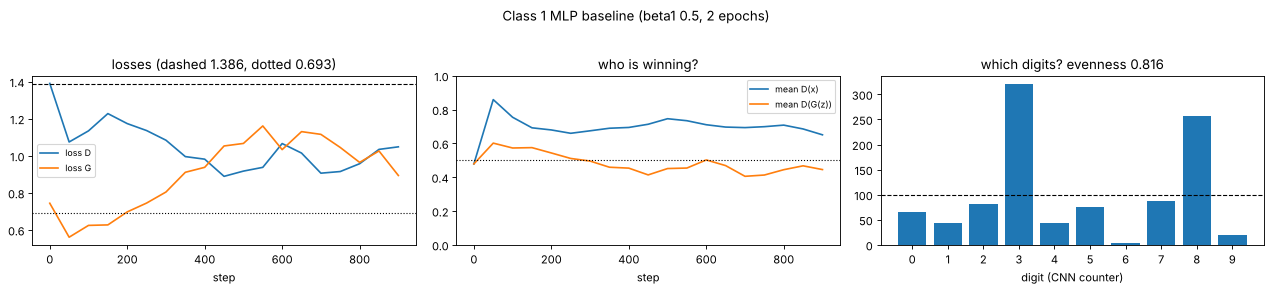

Class 1 MLP baseline (beta1 0.5, 2 epochs): counts {0: 66, 1: 44, 2: 82, 3: 321, 4: 43, 5: 76, 6: 4, 7: 87, 8: 257, 9: 20}
   evenness 0.816 | rarest digit 6 (4 of 1,000) | second-epoch mean D(x) 0.70, mean D(G(z)) 0.45


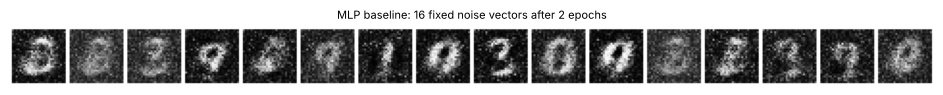

In [4]:
class MLPGenerator(nn.Module):                    # Class 1 Generator
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(100, 256), nn.ReLU(), nn.Linear(256, 784), nn.Tanh())
    def forward(self, z):
        return self.fc(z).view(-1, 1, 28, 28)


class MLPDiscriminator(nn.Module):                # Class 1 Discriminator, raw score out
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(784, 256), nn.LeakyReLU(0.2), nn.Linear(256, 1))
    def forward(self, x):
        return self.fc(x.view(-1, 784))


def n_params(m):
    return sum(p.numel() for p in m.parameters())

torch.manual_seed(0)
G_mlp, D_mlp = MLPGenerator(), MLPDiscriminator()
print(f"parameters: G {n_params(G_mlp):,}  D {n_params(D_mlp):,}")
log_mlp = train_gan(G_mlp, D_mlp, epochs=2)
counts_mlp = show_diagnostics(G_mlp, log_mlp, "Class 1 MLP baseline (beta1 0.5, 2 epochs)")
show_grid(log_mlp["grids"][-1][:16], nrow=16, title="MLP baseline: 16 fixed noise vectors after 2 epochs", size=16)

**Exercise 1 · Diagnose the baseline** (quality, variety, balance, edges). Guide's run: *grey, speckled, blurry digits; counts {0: 77, 1: 39, 2: 87, 3: 225, 4: 17, 5: 67, 6: 0, 7: 104, 8: 362, 9: 22}; mean D(x) about 0.7, D(G(z)) about 0.4.*

**This run:** counts {0: 66, 1: 44, 2: 82, 3: 321, 4: 43, 5: 76, 6: 4, 7: 87, 8: 257, 9: 20}, **evenness 0.816** (guide 0.786), second-epoch mean D(x) 0.70 and D(G(z)) 0.45. The same picture as the guide's run:
- **Quality:** blurry strokes on a **speckled grey background**; several samples are only half-formed.
- **Variety:** **partial collapse**: 3s (321) and 8s (257) dominate and there are almost no 6s (4 of 1,000; the guide's run had none) or 9s (20). All digits exist, but very unevenly.
- **Balance:** a live contest, nobody winning easily (D(x) ≈ 0.7, D(G(z)) ≈ 0.45, close to the guide's 0.7 / 0.4).
- **Edges:** grey noise right to the image border, where real digits are pure black, because each of the 784 outputs is learned separately: no pixel knows its neighbours are black.

## Part 2 · Convolution shapes
Two formulas give every layer's output size, for a square input of size n, kernel k, stride s and padding p:

| Layer | Output size | With k = 4, s = 2, p = 1 |
|---|---|---|
| `Conv2d` | **(n + 2p − k) // s + 1** | halves: 28 → 14 → 7 |
| `ConvTranspose2d` | **(n − 1)·s − 2p + k** | doubles: 7 → 14 → 28 |

> ✏️ **Predict:** `ConvTranspose2d(100, 128, kernel 7, stride 1, padding 0)` on a 1×1 input gives what size?

In [5]:
def conv_out(n, k, s, p):
    return (n + 2 * p - k) // s + 1

def convT_out(n, k, s, p):
    return (n - 1) * s - 2 * p + k

print("D (Conv2d k4 s2 p1):          28 ->", conv_out(28, 4, 2, 1), "->", conv_out(conv_out(28, 4, 2, 1), 4, 2, 1))
print("D last layer Conv2d(k7 s1 p0): 7 ->", conv_out(7, 7, 1, 0))
print("G first layer ConvT(k7 s1 p0): 1 ->", convT_out(1, 7, 1, 0))
print("G (ConvT k4 s2 p1):            7 ->", convT_out(7, 4, 2, 1), "->", convT_out(convT_out(7, 4, 2, 1), 4, 2, 1))

# check two of them with real PyTorch layers
z = torch.randn(1, 100, 1, 1)
h = nn.ConvTranspose2d(100, 128, 7, 1, 0)(z);  print("real layer:", tuple(h.shape))
h = nn.ConvTranspose2d(128, 64, 4, 2, 1)(h);   print("real layer:", tuple(h.shape))

D (Conv2d k4 s2 p1):          28 -> 14 -> 7
D last layer Conv2d(k7 s1 p0): 7 -> 1
G first layer ConvT(k7 s1 p0): 1 -> 7
G (ConvT k4 s2 p1):            7 -> 14 -> 28
real layer: (1, 128, 7, 7)
real layer: (1, 64, 14, 14)


**Answer:** (1 − 1)·1 − 0 + 7 = **7**. That is how G turns a noise vector into a 7×7 feature map.

### The stamp demo: what a transposed convolution does
A `ConvTranspose2d(1, 1, 4, 2, 1)` with **every weight set to 1** is applied to the 2×2 input [[1, 0], [0, 2]].

> ✏️ **Predict** the 4×4 output before running. Hint: each input pixel stamps a 4×4 block of its own value, two output pixels apart; padding trims a 1-pixel border; overlaps **add**.

input:
 [[1. 0.]
 [0. 2.]]
output:
 [[1. 1. 1. 0.]
 [1. 3. 3. 2.]
 [1. 3. 3. 2.]
 [0. 2. 2. 2.]]


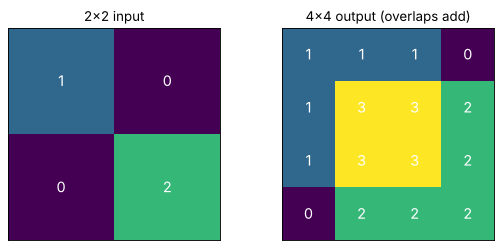

In [6]:
stamp = nn.ConvTranspose2d(1, 1, 4, 2, 1, bias=False)
with torch.no_grad():
    stamp.weight.fill_(1.0)
x = torch.tensor([[[[1., 0.], [0., 2.]]]])
out = stamp(x).detach()[0, 0]
print("input:\n", x[0, 0].numpy())
print("output:\n", out.numpy())

fig, ax = plt.subplots(1, 2, figsize=(7, 3.2))
for a, m, t in [(ax[0], x[0, 0], "2x2 input"), (ax[1], out, "4x4 output (overlaps add)")]:
    a.imshow(m, cmap="viridis", vmin=0, vmax=3)
    for (i, j), v in np.ndenumerate(m.numpy()):
        a.text(j, i, f"{v:.0f}", ha="center", va="center", color="w", fontsize=13)
    a.set_title(t); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

Output **[[1, 1, 1, 0], [1, 3, 3, 2], [1, 3, 3, 2], [0, 2, 2, 2]]**, as in the guide. The top-left pixel (1) stamps 1s, the bottom-right pixel (2) stamps 2s two pixels further along, and **the centre is 1 + 2 = 3** where they overlap. In a real generator the kernels are **learned**, so each feature stamps a learned patch of strokes.

### Exercise 2
**(a) Trace the Class 1 CelebA skeleton.** The Class 1 notebook (cells 6–7) gave only this generator for the DCGAN face mini-project:

In [7]:
class DCGANGenerator(nn.Module):          # Class 1 notebook, cell 7 (as quoted in the Class 1 guide)
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(100, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )
    def forward(self, x):
        return self.net(x)

h = torch.randn(2, 100, 1, 1)           # the noise must be shaped (batch, 100, 1, 1)
print("input", tuple(h.shape))
for layer in DCGANGenerator().net:
    h = layer(h)
    if isinstance(layer, nn.ConvTranspose2d):
        print(f"{str(layer):62s} -> {tuple(h.shape)}")

input (2, 100, 1, 1)
ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False) -> (2, 512, 4, 4)
ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False) -> (2, 256, 8, 8)
ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False) -> (2, 128, 16, 16)
ConvTranspose2d(128, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False) -> (2, 3, 32, 32)


1×1 → **4** (k4 s1 p0: (1 − 1)·1 + 4) → **8** → **16** → **32**, with 3 colour channels at the end: the final image is **[B, 3, 32, 32]**.

**(b) How many layers for 64×64?** **One more** `ConvTranspose2d(…, 4, 2, 1)` (32 → 64), the standard DCGAN face size; e.g. widen the first layer to 100 → 512, then 512 → 256 → 128 → 64 → 3. That is assignment option B (CelebA). CelebA cannot be downloaded on this machine and needs a GPU to train in reasonable time. On your own machine or Colab (GPU runtime): download the aligned CelebA images (the `torchvision.datasets.CelebA(root, download=True)` helper often fails because of Google Drive download limits; the Kaggle copy "celeba-dataset" is a common alternative), load the folder with `datasets.ImageFolder`, use `transforms.Resize(64)`, `transforms.CenterCrop(64)`, `ToTensor()` and `Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))`, and write a mirror D with **3 input channels** (64 → 32 → 16 → 8 → 4 → 1 score). The training loop is `train_gan()` unchanged.

**(c) Why are the stamp centres larger? And what are checkerboard artifacts?** The four centre values are 3 because stamps from both input pixels overlap there (1 + 2). When the **kernel size is not divisible by the stride**, some output pixels receive more overlapping stamps than others, and a faint grid appears in generated images: **checkerboard artifacts** (Odena, Dumoulin and Olah, Distill 2016). Kernel 4 with stride 2 overlaps evenly. We can see it by feeding an all-ones input through all-ones kernels:

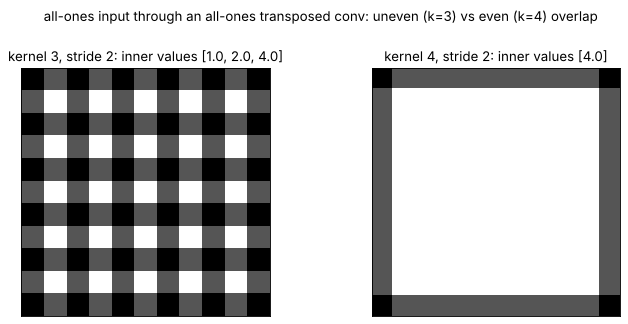

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, k in zip(ax, [3, 4]):
    layer = nn.ConvTranspose2d(1, 1, k, 2, 1, bias=False)
    with torch.no_grad():
        layer.weight.fill_(1.0)
        o = layer(torch.ones(1, 1, 6, 6))[0, 0]
    a.imshow(o, cmap="gray"); a.set_xticks([]); a.set_yticks([])
    inner = o[2:-2, 2:-2]
    a.set_title(f"kernel {k}, stride 2: inner values {sorted(set(inner.flatten().tolist()))}")
plt.suptitle("all-ones input through an all-ones transposed conv: uneven (k=3) vs even (k=4) overlap", y=1.0)
plt.tight_layout(); plt.show()

With kernel 3 and stride 2 the inner pixels receive 1, 2 or 4 overlapping stamps: a **checkerboard**. With kernel 4 and stride 2 every inner pixel receives exactly 4: flat. That is why DCGANs use k4 s2 p1.

## Part 3 · The DCGAN
### Why convolutions?
The Class 1 generator treats an image as 784 unrelated numbers: **each output pixel is learned on its own**, so no pixel knows its neighbours are black (grey speckle) and a "stroke" means nothing to a Linear layer. A convolution adds two assumptions that fit images:
- **Locality:** each output pixel is computed from a small neighbourhood (a 4×4 window), so neighbours decide together and backgrounds come out smooth.
- **Weight sharing:** the same filter slides over the whole image, so a stroke is learned once, not once per position.

### The two networks (exactly the guide's table)

| Network | Layer | Output shape |
|---|---|---|
| G | input z, reshaped with `z.view(B, -1, 1, 1)` | [B, 100, 1, 1] |
| G | `ConvTranspose2d(100, 128, 7, 1, 0)` + BatchNorm + ReLU | [B, 128, 7, 7] |
| G | `ConvTranspose2d(128, 64, 4, 2, 1)` + BatchNorm + ReLU | [B, 64, 14, 14] |
| G | `ConvTranspose2d(64, 1, 4, 2, 1)` + Tanh | [B, 1, 28, 28] |
| D | `Conv2d(1, 64, 4, 2, 1)` + LeakyReLU(0.2) | [B, 64, 14, 14] |
| D | `Conv2d(64, 128, 4, 2, 1)` + BatchNorm + LeakyReLU(0.2) | [B, 128, 7, 7] |
| D | `Conv2d(128, 1, 7, 1, 0)`, then `.view(-1, 1)` | [B, 1]: one raw score |

G grows the image while the channel count shrinks; D is the mirror. `bias=False` is used before BatchNorm because BatchNorm has its own shift. `in_dim` and `in_channels` are arguments so Part 4 can reuse these classes with extra label inputs.

In [9]:
class DCGenerator(nn.Module):
    def __init__(self, in_dim=Z_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(in_dim, 128, 7, 1, 0, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),   # 1 -> 7
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True),        # 7 -> 14
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False), nn.Tanh())                                  # 14 -> 28
    def forward(self, z):
        return self.net(z.view(z.size(0), -1, 1, 1))


class DCDiscriminator(nn.Module):
    def __init__(self, in_channels=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),                   # 28 -> 14
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),      # 14 -> 7
            nn.Conv2d(128, 1, 7, 1, 0, bias=False))                                                     # 7 -> 1
    def forward(self, x):
        return self.net(x).view(-1, 1)


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

`init_weights` sets every conv weight from **N(0, 0.02)** and BatchNorm scales from N(1, 0.02), as in the DCGAN paper.

**Shape check:** one batch through G and D, printing every layer's shape, and the parameter counts.

In [10]:
torch.manual_seed(0)
G_dc, D_dc = DCGenerator(), DCDiscriminator()
G_dc.apply(init_weights); D_dc.apply(init_weights)

h = torch.randn(4, Z_DIM).view(4, -1, 1, 1)
print("G: z", tuple(h.shape))
for layer in G_dc.net:
    h = layer(h)
    if isinstance(layer, (nn.ConvTranspose2d, nn.Tanh)): print(f"   {layer.__class__.__name__:16s} -> {tuple(h.shape)}")
print("D: image", tuple(h.shape))
for layer in D_dc.net:
    h = layer(h)
    if isinstance(layer, nn.Conv2d): print(f"   {layer.__class__.__name__:16s} -> {tuple(h.shape)}")
print(f"\nparameters   MLP G {n_params(G_mlp):>8,}   DCGAN G {n_params(G_dc):>8,}  ({n_params(G_dc) / n_params(G_mlp):.1f}x)")
print(f"             MLP D {n_params(D_mlp):>8,}   DCGAN D {n_params(D_dc):>8,}  ({1 - n_params(D_dc) / n_params(D_mlp):.0%} smaller)")

G: z (4, 100, 1, 1)
   ConvTranspose2d  -> (4, 128, 7, 7)


   ConvTranspose2d  -> (4, 64, 14, 14)
   ConvTranspose2d  -> (4, 1, 28, 28)
   Tanh             -> (4, 1, 28, 28)
D: image (4, 1, 28, 28)
   Conv2d           -> (4, 64, 14, 14)
   Conv2d           -> (4, 128, 7, 7)
   Conv2d           -> (4, 1, 1, 1)

parameters   MLP G  227,344   DCGAN G  759,680  (3.3x)
             MLP D  201,217   DCGAN D  138,624  (31% smaller)


The convolutional D is **smaller** than the MLP's, yet a much better critic: each small filter is reused across the whole image. A better critic is a better teacher, because G only learns through D's gradient.

### The DCGAN rules and why

| Rule | Why it helps |
|---|---|
| strided convolutions, no pooling | the network learns how to shrink and grow |
| BatchNorm in G and D | stable activations; the paper credits it with preventing G collapsing to a single point |
| no BatchNorm on G's output or D's input | BN on every layer caused sample oscillation and instability |
| ReLU in G, Tanh output | output in [−1, 1], matching the normalised images |
| LeakyReLU(0.2) in D | gradients still flow for negative inputs |
| Adam lr 0.0002, β1 = 0.5 | β1 = 0.9 caused oscillation (Class 2 & 3 Run A) |
| weights from N(0, 0.02) | a small, standard start |

> ✏️ **Predict:** after the same 2 epochs, will the DCGAN's digits look cleaner than the MLP's? Will the histogram be more even?

epoch 1/2: loss D 0.217, loss G 2.262  (124 s)


epoch 2/2: loss D 0.773, loss G 1.834  (245 s)


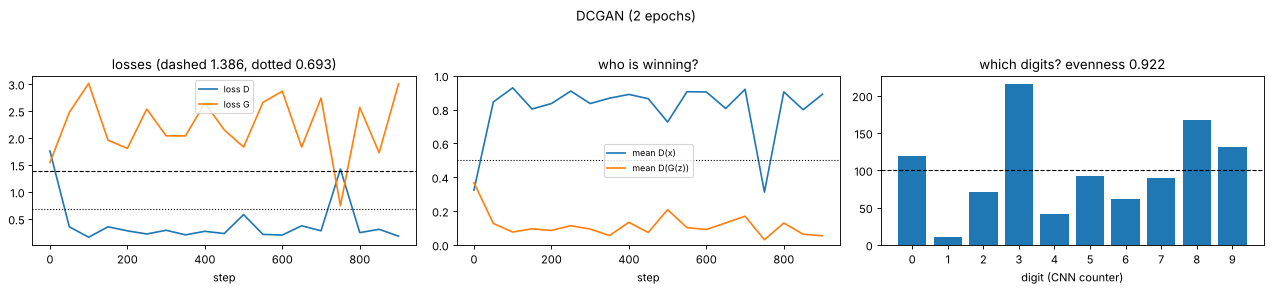

DCGAN (2 epochs): counts {0: 119, 1: 10, 2: 71, 3: 216, 4: 41, 5: 92, 6: 62, 7: 90, 8: 168, 9: 131}
   evenness 0.922 | rarest digit 1 (10 of 1,000) | second-epoch mean D(x) 0.80, mean D(G(z)) 0.11


In [11]:
log_dc = train_gan(G_dc, D_dc, epochs=2)
counts_dc = show_diagnostics(G_dc, log_dc, "DCGAN (2 epochs)")

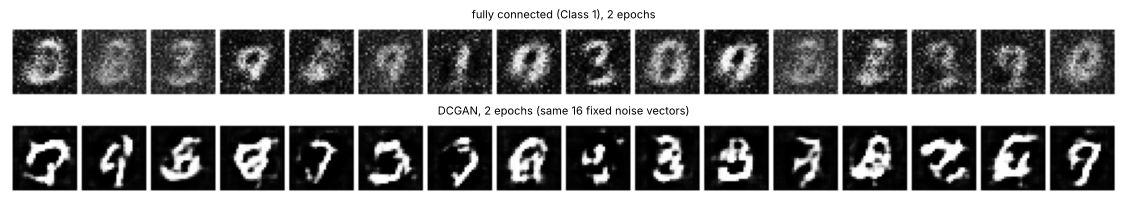

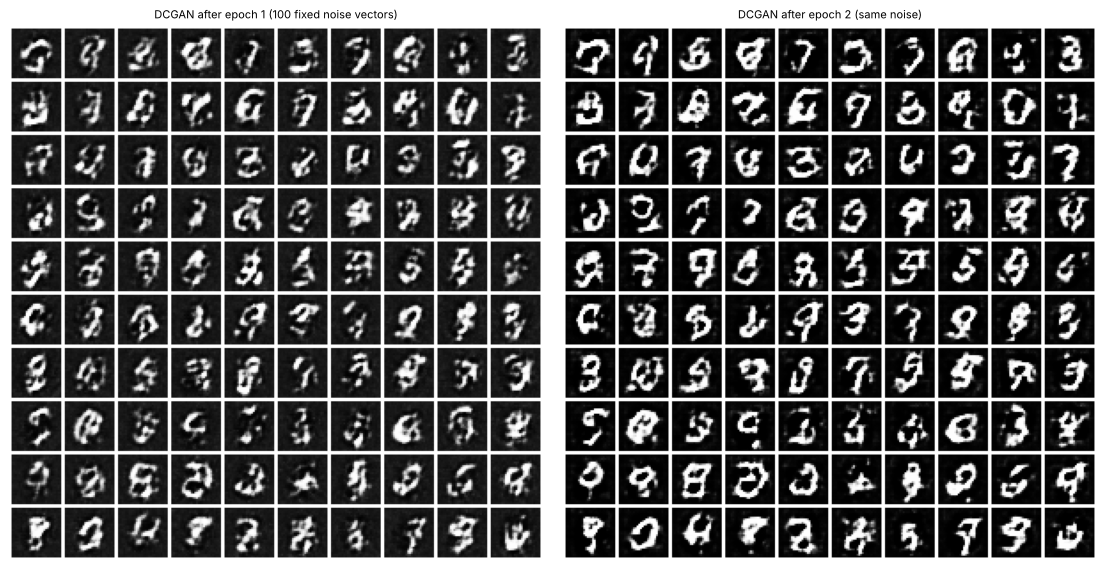

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(16, 2.6))
show_grid(log_mlp["grids"][-1][:16], nrow=16, title="fully connected (Class 1), 2 epochs", ax=ax[0])
show_grid(log_dc["grids"][-1][:16], nrow=16, title="DCGAN, 2 epochs (same 16 fixed noise vectors)", ax=ax[1])
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
show_grid(log_dc["grids"][0], title="DCGAN after epoch 1 (100 fixed noise vectors)", ax=ax[0])
show_grid(log_dc["grids"][1], title="DCGAN after epoch 2 (same noise)", ax=ax[1])
plt.tight_layout(); plt.show()

**What happened (this run).** - **Quality:** **clean black backgrounds and solid, connected strokes**, no speckle. Several samples are still malformed, because 2 epochs is short (real DCGAN runs train for 25 or more).
- **Variety:** all ten digits appear: {0: 119, 1: 10, 2: 71, 3: 216, 4: 41, 5: 92, 6: 62, 7: 90, 8: 168, 9: 131}. **Evenness 0.922** (guide 0.929) vs the MLP's 0.816. Rarest digit: **1, with 10 of 1,000** (guide: 1, with 12), vs the MLP's 6 (4 of 1,000).
- **Balance:** mean D(x) mostly 0.8–0.93, mean D(G(z)) mostly 0.05–0.2 (one brief swing near step 750 where they crossed). D is clearly ahead, but D(G(z)) is not stuck at 0 and the samples improve, so G still gets a useful gradient: **case d (healthy)** from the revision checkpoint. Epoch-end losses: D 0.217 / G 2.262, then D 0.773 / G 1.834 (guide: 0.213 / 2.739, then 0.258 / 2.147; last-batch losses are noisy snapshots).

### Exercise 3 · MLP vs DCGAN

| | Fully connected (Class 1) | DCGAN | Guide's run (MLP → DCGAN) |
|---|---|---|---|
| parameters G / D | 227,344 / 201,217 | 759,680 (3.3×) / 138,624 (31% smaller) | same counts |
| look of samples | grey speckle, blurry, broken strokes | black background, solid connected strokes, some malformed shapes | same |
| evenness (1,000 samples) | 0.816 | **0.922** | 0.786 → 0.929 |
| rarest digit | 6 (4 of 1,000) | 1 (10 of 1,000) | 6 (0) → 1 (12) |
| mean D(x) / D(G(z)), epoch 2 | ≈ 0.70 / 0.45 | ≈ 0.80 / 0.11 | ≈ 0.7 / 0.4 → ≈ 0.9 / 0.15 |

A smaller D gives a better critic: each filter is reused across the whole image, so it gets more useful features from fewer weights, and a better critic is a better teacher for G.

**Epoch 1 vs epoch 2:** after epoch 1 the strokes are thinner, greyer and often broken; after epoch 2 (same noise vectors) they are brighter, thicker and more connected, and more cells are readable digits. The model is clearly still improving.

**Optional (not run here to save time):** retrain with `betas=(0.9, 0.999)`, or remove the BatchNorm layers from G. The guide warns results vary by machine and seed: report what you see and connect it to Class 2 & 3's Run A; do not expect a guaranteed collapse.

## Part 4 · The conditional DCGAN: choose the digit
Classes 1, 2 and 3 looped `for real, _ in train_loader`: the `_` **is the digit label**, thrown away. An unconditional G(z) gives *some* digit, chosen by chance. To get a 7 you would have to sample, classify and throw away nine out of ten.

A **conditional GAN** plays the same minimax game with the label y added everywhere:

  **min over G, max over D of  E[log D(x, y)] + E[log(1 − D(G(z, y), y))]**

- **G(z, y)** = "draw digit y in style z".
- **D(x, y)** asks "is x a real image **of digit y**?", so it rejects two kinds of mistake: images that look fake, and real-looking images of the **wrong digit**.
- If only G had the label, D would accept a perfect 3 labelled "7", G would get no signal to obey y, and it would learn to **ignore** it. So **the label must go to both players.**

### How the label goes in

| Class | Change from the DCGAN | Code |
|---|---|---|
| `CondDCGenerator` | **110** input channels: 100 noise + 10 one-hot | `torch.cat([z, one_hot(y, 10)], dim=1)` |
| `CondDCDiscriminator` | **11** input channels: the image + 10 label maps of 28×28, the true label's map all ones | `torch.cat([x, y_maps], dim=1)` |

Everything else is the DCGAN unchanged.

D's input for one real 5: (11, 28, 28)


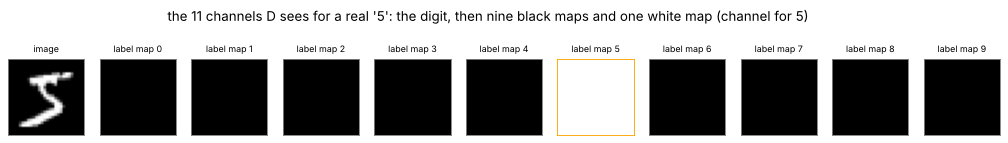

In [13]:
class CondDCGenerator(DCGenerator):
    def __init__(self):
        super().__init__(in_dim=Z_DIM + 10)                        # 110 input channels
    def forward(self, z, y):
        zy = torch.cat([z, F.one_hot(y, 10).float()], dim=1)       # [B, 100] + [B, 10] -> [B, 110]
        return super().forward(zy)


class CondDCDiscriminator(DCDiscriminator):
    def __init__(self):
        super().__init__(in_channels=1 + 10)                       # image + 10 label maps
    def forward(self, x, y):
        y_maps = F.one_hot(y, 10).float()[:, :, None, None].expand(-1, 10, 28, 28)   # [B, 10, 28, 28]
        return super().forward(torch.cat([x, y_maps], dim=1))      # [B, 11, 28, 28]


# what D receives for a real "5"
idx5 = int((train_data.targets == 5).nonzero()[0])
x5, y5 = train_data[idx5]
y_maps = F.one_hot(torch.tensor([y5]), 10).float()[:, :, None, None].expand(-1, 10, 28, 28)
d_input = torch.cat([x5[None], y_maps], dim=1)[0]
print("D's input for one real 5:", tuple(d_input.shape))
fig, axes = plt.subplots(1, 11, figsize=(16, 1.9))
for c in range(11):
    axes[c].imshow(d_input[c], cmap="gray", vmin=-1 if c == 0 else 0, vmax=1)
    axes[c].set_title("image" if c == 0 else f"label map {c - 1}", fontsize=8); axes[c].set_xticks([]); axes[c].set_yticks([])
    for s in axes[c].spines.values(): s.set_edgecolor("orange" if c == 6 else "grey")
plt.suptitle("the 11 channels D sees for a real '5': the digit, then nine black maps and one white map (channel for 5)", y=1.08)
plt.show()

> ✏️ **Predict:** in `train_gan(..., conditional=True)`, G draws the **real batch's labels**, and D scores each fake **with the same label**. What would go wrong if D scored each fake with a *different*, random label?

**Answer (from the guide).** D would mostly see mismatched pairs and could learn "mismatch = fake" as a shortcut; worse, G's gradient would push it towards the label D used, not the one G was given, so G could never learn to obey y.

parameters: G 822,400  D 148,864


epoch 1/2: loss D 1.193, loss G 2.262  (148 s)


epoch 2/2: loss D 0.940, loss G 2.061  (295 s)


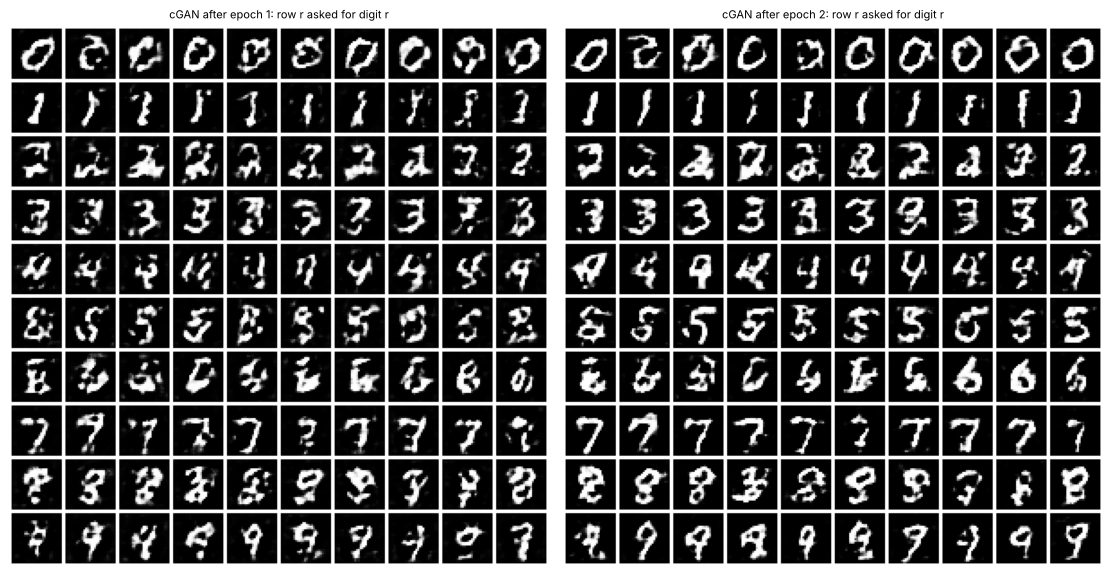

In [14]:
torch.manual_seed(0)
G_c, D_c = CondDCGenerator(), CondDCDiscriminator()
G_c.apply(init_weights); D_c.apply(init_weights)
print(f"parameters: G {n_params(G_c):,}  D {n_params(D_c):,}")
log_c = train_gan(G_c, D_c, epochs=2, conditional=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 7.3))
show_grid(log_c["grids"][0], title="cGAN after epoch 1: row r asked for digit r", ax=ax[0])
show_grid(log_c["grids"][1], title="cGAN after epoch 2: row r asked for digit r", ax=ax[1])
plt.tight_layout(); plt.show()

**What happened (this run).** Already after epoch 1, row r shows digit r in almost every cell; after epoch 2 the shapes are cleaner. **Within a row the samples differ** (thick, thin, slanted, open, closed): that variety comes from z. The weakest rows are 2, 8 and 9 (and a few malformed 6s). As the guide says, the shapes look cleaner than the unconditional DCGAN's after the same training: knowing the digit makes G's job easier. Epoch-end losses: D 1.193 / G 2.262, then D 0.940 / G 2.061 (guide: 1.413 / 2.623, then 0.856 / 0.844).

### 4.1 · Conditional accuracy: did G obey the label?
`conditional_accuracy(G_c)` generates **100 samples per digit** and counts how many the CNN counter reads as the requested digit.

conditional accuracy: 84.4%  (guide's run: 84.4%)
digit           0    1    2    3    4    5    6    7    8    9
accuracy (%)   91   92   82   76   83   87   92   98   78   65
guide (%)      97   92   84   82   73   88   82   93   84   69
largest confusions (asked -> seen, out of 100): 2 -> 3 (16), 3 -> 5 (13), 9 -> 7 (11), 9 -> 3 (11), 8 -> 3 (11)


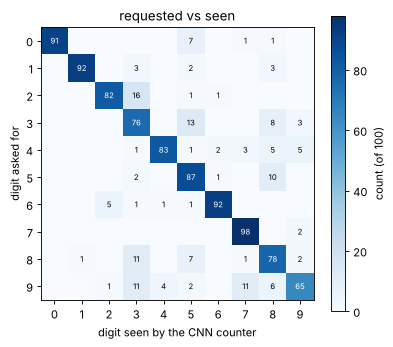

In [15]:
def conditional_accuracy(G, n_per_digit=100, seed=2):
    gen = torch.Generator().manual_seed(seed)
    asked = torch.arange(10).repeat_interleave(n_per_digit)
    z = torch.randn(len(asked), Z_DIM, generator=gen)
    seen = classify(generate(G, z.to(device), asked.to(device)))
    confusion = np.zeros((10, 10), int)                     # rows = asked, columns = seen
    for a, s in zip(asked.tolist(), seen.tolist()):
        confusion[a, s] += 1
    return (seen == asked).float().mean().item(), confusion


acc_c, conf_c = conditional_accuracy(G_c)
print(f"conditional accuracy: {acc_c:.1%}  (guide's run: 84.4%)")
print("digit        " + " ".join(f"{d:>4d}" for d in range(10)))
print("accuracy (%) " + " ".join(f"{conf_c[d, d]:>4d}" for d in range(10)))
print("guide (%)    " + " ".join(f"{v:>4d}" for v in [97, 92, 84, 82, 73, 88, 82, 93, 84, 69]))
off = [(conf_c[a, s], a, s) for a in range(10) for s in range(10) if a != s]
print("largest confusions (asked -> seen, out of 100):", ", ".join(f"{a} -> {s} ({n})" for n, a, s in sorted(off, reverse=True)[:5]))

plt.figure(figsize=(5.5, 4.8))
plt.imshow(conf_c, cmap="Blues"); plt.colorbar(label="count (of 100)")
for (a, s), v in np.ndenumerate(conf_c):
    if v: plt.text(s, a, v, ha="center", va="center", fontsize=7, color="w" if v > 50 else "k")
plt.xticks(range(10)); plt.yticks(range(10)); plt.xlabel("digit seen by the CNN counter"); plt.ylabel("digit asked for")
plt.title("requested vs seen"); plt.show()

**This run: 84.4%**, the same headline number as the guide's run (84.4%). That is partly coincidence: the per-digit split differs. Ours is best for 7 (98%), 1 and 6 (92%), and worst for **9 (65%)**, 3 (76%) and 8 (78%); the guide's was best for 0 (97%) and 7 (93%), worst for 9 (69%) and 4 (73%). Largest confusions here: 2 → 3 (16), 3 → 5 (13), 9 → 7 (11), 9 → 3 (11), 8 → 3 (11); three of the guide's four pairs (9 → 7, 2 → 3, 3 → 5) appear again. These pairs share strokes. Part of the 15.6% is the counter's own error on unusual handwriting (it is 98.1% accurate on real digits).

### 4.2 · Content vs style
`style_vs_content` uses **one noise vector per row** with labels 0–9 across the columns. If the label controls content and the noise controls style, each row should show ten different digits **in the same handwriting**.

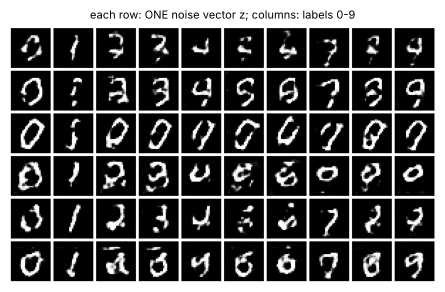

In [16]:
def style_vs_content(G, n_rows=6, seed=3):
    z = torch.randn(n_rows, Z_DIM, generator=torch.Generator().manual_seed(seed))
    z = z.repeat_interleave(10, dim=0)                     # each z used 10 times...
    y = torch.arange(10).repeat(n_rows)                    # ...with labels 0..9
    show_grid(generate(G, z.to(device), y.to(device)), nrow=10, title="each row: ONE noise vector z; columns: labels 0-9", size=7)
    plt.show()

style_vs_content(G_c)

**Content vs style (this run).** Along each row the **digit** changes with the label while the **handwriting** stays similar: row 2 has thin strokes, row 3 thick, bold loops, row 6 neat medium strokes. The label controls content; the noise controls style. Some noise vectors give messy styles after only 2 epochs: in row 3 the labels 2 to 4, and in row 4 the labels 7 to 9, come out as round, 0-like loops, so those z's encode a "round" style that G cannot yet combine with every digit.

### 4.3 · Interpolation
`interpolate` keeps the **label fixed** and walks z in 10 steps in a straight line from z_a to z_b.

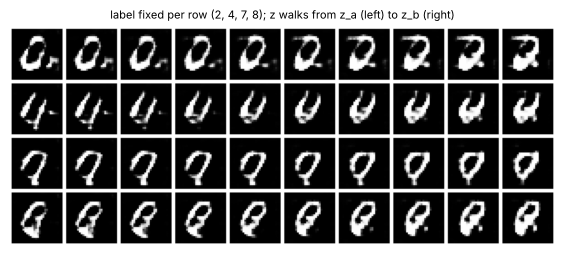

In [17]:
def interpolate(G, label, steps=10, seed=4):
    gen = torch.Generator().manual_seed(seed)
    z_a, z_b = torch.randn(1, Z_DIM, generator=gen), torch.randn(1, Z_DIM, generator=gen)
    t = torch.linspace(0, 1, steps).view(-1, 1)
    z = (1 - t) * z_a + t * z_b
    return generate(G, z.to(device), torch.full((steps,), label, device=device))

rows = torch.cat([interpolate(G_c, d) for d in [2, 4, 7, 8]])
show_grid(rows, nrow=10, title="label fixed per row (2, 4, 7, 8); z walks from z_a (left) to z_b (right)", size=9)
plt.show()

**Interpolation (this run).** With the label fixed, the image changes **gradually** from left to right: slant, thickness and loop shape morph step by step, with no sudden jumps. G has learned a smooth style space (a theme of the VAE module next class). Not every intermediate is clean: the "2" row starts from a 0-like loop that only becomes a clear 2 towards the right, another sign that 2 epochs is short training.

### Exercise 4
1. **Your conditional accuracy, hardest digits and their confusions:** **84.4%** in this run (80–90% after 2 epochs is typical, says the guide). Hardest digits: 9 (65%, often seen as 7 or 3), 3 (76%, seen as 5) and 8 (78%, seen as 3).
2. **What does one z fix across all ten digits?** The handwriting **style**: thickness, slant, size, loop shape (Part 4.2).
3. **Mismatch test:** does D check the **match** between image and label, or only realism? Score 200 generated 7s with label 7 and with label 1.

In [18]:
D_c.eval()
z = torch.randn(200, Z_DIM, generator=torch.Generator().manual_seed(5)).to(device)
sevens = generate(G_c, z, torch.full((200,), 7, device=device)).to(device)
with torch.no_grad():
    s7 = torch.sigmoid(D_c(sevens, torch.full((200,), 7, device=device))).mean().item()
    s1 = torch.sigmoid(D_c(sevens, torch.full((200,), 1, device=device))).mean().item()
D_c.train()
print(f"D's mean P(real) for 200 generated 7s:  labelled 7 -> {s7:.3f}   labelled 1 -> {s1:.3f}   (guide: 0.315 vs 0.141)")

D's mean P(real) for 200 generated 7s:  labelled 7 -> 0.248   labelled 1 -> 0.063   (guide: 0.315 vs 0.141)


**Answer (this run):** D's mean P(real) for the same 200 generated 7s is **0.248 with label 7** and **0.063 with label 1** (guide: 0.315 vs 0.141). The image is identical; only the label changed, and D's score dropped about fourfold. **D has learned the image–label match**, not only realism. That is exactly the signal that teaches G to obey y. (Both numbers are well below 0.5 because D is ahead of G, as in Part 3.)

4. **Can a cGAN still collapse?** Yes: it can collapse **within a class** (every 7 identical). A row of the 10×10 grid or the style-vs-content grid shows it; **conditional accuracy does not**, because it measures control, not variety. In our grids there is no sign of within-class collapse yet: every row of the 10×10 grid contains clearly different handwriting.

## Part 5 · Wrap-up

### What changed from the unconditional GAN (summary for the viva)
| | Unconditional (Classes 1–3, Part 3) | Conditional (Part 4) |
|---|---|---|
| data loop | `for real, _ in train_loader` (label thrown away) | `for real, labels in train_loader` (label used) |
| G's input | z: 100 numbers | z + one-hot(y): 110 numbers |
| D's input | the image (1 channel) | the image + 10 label maps (11 channels) |
| D's question | "is x real?" | "is x a real image **of digit y**?" |
| D step | real → 1, G(z) → 0 | (real, its label) → 1, (G(z, y), y) → 0 |
| G step | make D(G(z)) → 1 | make D(G(z, y), y) → 1 |
| what you control | nothing: the digit is chosen by chance | **content** by y, **style** by z |
| new measurement | digit histogram (variety) | conditional accuracy (control) |

The loss function, optimiser, alternating D/G steps and architecture body are **unchanged**.

### Reflection questions (model answers)
1. **Why does the fully connected G leave speckle?** It learns each of the 784 outputs separately, so neighbouring background pixels never agree. Convolutions compute each output from a small neighbourhood with shared filters, so backgrounds come out smooth and strokes connected.
2. **`ConvTranspose2d(k=4, s=2, p=1)` on 16×16?** (16 − 1)·2 − 2 + 4 = **32×32**. This choice exactly doubles any size and mirrors `Conv2d(k=4, s=2, p=1)`, which exactly halves, so G and D can be mirror images.
3. **Why must D see the label?** To reject realistic digits of the wrong class. If only G had the label, G would get no signal to obey it and would learn to ignore y.
4. **Can a cGAN collapse?** Yes, within a class (all 7s identical). The rows of the 10×10 grid or the style-vs-content grid show it.

### Exit ticket (from the slides) with answers
1. *D(x) ≈ 0.99 and D(G(z)) ≈ 0.01 for 2,000 steps; the grid is frozen.* D too strong; vanishing gradient for G.
2. *`ConvTranspose2d(k4, s2, p1)` layers after a 7×7 start: size after two of them?* **28×28** (7 → 14 → 28).
3. *In a cGAN, what does D receive, and why does it need the label?* The image + label maps; otherwise G ignores y.
4. *Fixed z, labels 0 to 9: what stays the same across the row?* The style (thickness, slant).

### Assignment (choose one)

| Option | Task | Submit |
|---|---|---|
| A · Fashion-MNIST | train today's DCGAN on `datasets.FashionMNIST` (same 28×28 size) | fixed-noise grid per epoch and a short note on what improved |
| B · DCGAN faces | extend the Class 1 `DCGANGenerator` to 64×64, write a mirror D, train on CelebA (GPU recommended; see Exercise 2b for how) | samples and a short discussion of failures seen |
| C · Embedding | replace the one-hot in `CondDCGenerator` with `nn.Embedding(10, 50)` | conditional accuracy compared with today's version |

### Assignment option C, done: `nn.Embedding(10, 50)` instead of one-hot
A one-hot label is a fixed code. An **embedding** is a small trainable table: each digit gets **50 learned numbers**, trained along with G, so G can learn its own description of each digit. G's input becomes 100 + 50 = **150** channels. D is left exactly as in Part 4 (image + 10 one-hot label maps), so only G's way of reading the label changes. Same seed, same 2 epochs.

epoch 1/2: loss D 0.700, loss G 2.297  (152 s)


epoch 2/2: loss D 1.227, loss G 1.656  (305 s)



conditional accuracy   one-hot (Part 4): 84.4%   nn.Embedding(10, 50): 78.7%
per digit, one-hot  : [91, 92, 82, 76, 83, 87, 92, 98, 78, 65]
per digit, embedding: [95, 67, 74, 79, 87, 89, 82, 83, 74, 57]


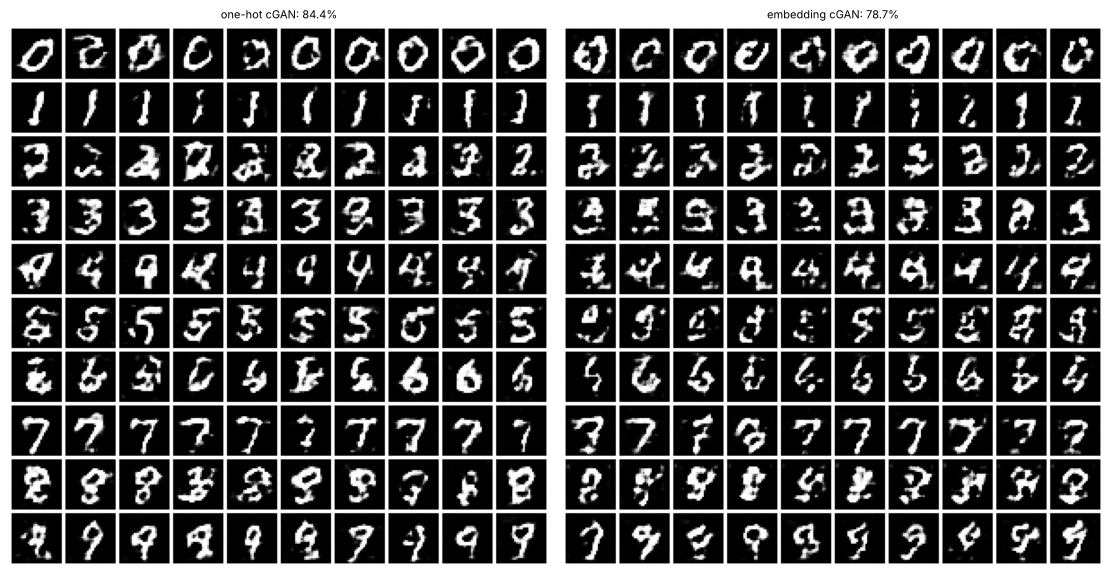

In [19]:
class EmbedDCGenerator(DCGenerator):
    def __init__(self, embed_dim=50):
        super().__init__(in_dim=Z_DIM + embed_dim)              # 150 input channels
        self.embed = nn.Embedding(10, embed_dim)                # a learned 50-number code per digit
    def forward(self, z, y):
        return super().forward(torch.cat([z, self.embed(y)], dim=1))

torch.manual_seed(0)
G_e, D_e = EmbedDCGenerator(), CondDCDiscriminator()
G_e.apply(init_weights); D_e.apply(init_weights)
log_e = train_gan(G_e, D_e, epochs=2, conditional=True)
acc_e, conf_e = conditional_accuracy(G_e)
print(f"\nconditional accuracy   one-hot (Part 4): {acc_c:.1%}   nn.Embedding(10, 50): {acc_e:.1%}")
print("per digit, one-hot  :", [int(conf_c[d, d]) for d in range(10)])
print("per digit, embedding:", [int(conf_e[d, d]) for d in range(10)])
fig, ax = plt.subplots(1, 2, figsize=(14, 7.3))
show_grid(log_c["grids"][-1], title=f"one-hot cGAN: {acc_c:.1%}", ax=ax[0])
show_grid(log_e["grids"][-1], title=f"embedding cGAN: {acc_e:.1%}", ax=ax[1])
plt.tight_layout(); plt.show()

**Result (this run, one seed, 2 epochs):** the embedding version reached **78.7%** conditional accuracy vs **84.4%** for one-hot. Per digit it was better for 0, 3, 4 and 5, but clearly worse for 1 (67% vs 92%), 2, 7, 8 and 9, and its grid looks messier.

**How to read this honestly:** the embedding is not "worse" in general. A one-hot code is a fixed, perfectly distinct signal from the first step, while the 50-number embedding starts random and must be **learned at the same time** as everything else; with only 2 epochs that is one more thing to learn. With longer training, the two usually end up similar; embeddings matter more when there are many classes (one-hot vectors grow with the number of classes, an embedding stays the size you choose). One run with one seed cannot settle it: for a proper submission, train both longer and on two or three seeds and compare the averages.

### Training time in this run

In [20]:
for name, log in [("MLP baseline", log_mlp), ("DCGAN", log_dc), ("conditional DCGAN", log_c), ("embedding cGAN (assignment C)", log_e)]:
    print(f"{name:30s} {log['seconds']:6.0f} s for 2 epochs")
print("guide (2-core CPU): MLP 18 s, DCGAN 153 s, cGAN 199 s")

MLP baseline                       19 s for 2 epochs
DCGAN                             245 s for 2 epochs
conditional DCGAN                 295 s for 2 epochs
embedding cGAN (assignment C)     305 s for 2 epochs
guide (2-core CPU): MLP 18 s, DCGAN 153 s, cGAN 199 s


These times depend heavily on the machine and on what else it is running. This notebook was executed on a shared 4-core CPU server that was busy with other jobs, so the times above are slower than the guide's 2-core test run. On a GPU (e.g. Colab with a GPU runtime) every cell runs in seconds. If training is too slow on your laptop, the guide suggests training Part 3 with `epochs=1` and keeping 2 epochs for Part 4.

**Next class:** autoencoders and VAEs (encoder, bottleneck, decoder, reconstruction loss).

*Source: reconstructed from the course guide "GAN Class 4 Notebook Explained" (GAN-Class-4-DCGAN-cGAN.ipynb) and the Class 4 slides; the DCGAN skeleton from the Class 1 guide (CV-Week4-Lecture1.ipynb, cells 6–8). Papers: Radford, Metz and Chintala 2015 (DCGAN); Mirza and Osindero 2014 (cGAN); Odena, Dumoulin and Olah 2016 (checkerboard artifacts).*